# 16. Capstone: pipe flow of a Carreau–Yasuda fluid

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/notebooks/16_capstone_carreau_yasuda.ipynb)

This notebook uses the whole course on one research-level problem, and reproduces the results of
a published paper:

> Y. Wang, *Steady isothermal flow of a Carreau–Yasuda model fluid in a straight circular tube*,
> Journal of Non-Newtonian Fluid Mechanics **310** (2022) 104937.
> [doi:10.1016/j.jnnfm.2022.104937](https://doi.org/10.1016/j.jnnfm.2022.104937)

Notebook 6 solved laminar pipe flow for Newtonian and power-law fluids. Real polymer melts and
solutions are neither: they are Newtonian at low shear rates and shear-thinning at high ones.
The Carreau–Yasuda model describes both regimes and the transition between them, and for a long
time its pipe flow was treated as a purely numerical problem. The paper shows that it has an
almost closed-form solution. Here SymPy finds that solution.

| Step | From notebook |
| --- | --- |
| limits and asymptotes of the viscosity model | 3 |
| scaling the problem | 10 |
| a proof for *any* viscosity law, using an undefined function | 11, 13.2 |
| an integral that needs a special function | 13.5 |
| one nonlinear equation solved numerically | 2 |
| `lambdify` with a hand-supplied translation | 8 |
| verification against limits, quadrature and published numbers | all |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import cumulative_trapezoid, quad
from scipy.optimize import brentq
from scipy.special import hyp2f1

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## 16.1 The fluid model

The Carreau–Yasuda viscosity depends on the shear rate $\dot\gamma$ through five parameters:

$$\eta(\dot\gamma) = \eta_\infty + (\eta_0 - \eta_\infty)\left[1 + (\lambda\dot\gamma)^a\right]^{(n-1)/a}.$$

$\eta_0$ and $\eta_\infty$ are the viscosities at very low and very high shear rate, $\lambda$
is a time constant, $n$ is the power-law index and $a$ sets how sharp the transition is
($a = 2$ is the Carreau model).

In [2]:
gamma_dot = sp.symbols("gammadot", positive=True)
eta_0, eta_inf, lam, a, n = sp.symbols("eta_0 eta_inf lambda a n", positive=True)

eta = eta_inf + (eta_0 - eta_inf) * (1 + (lam * gamma_dot) ** a) ** ((n - 1) / a)
eta

                                 n - 1
                                 ─────
                                   a  
                     ⎛     a    ⎞     
η_inf + (η₀ - η_inf)⋅⎝(γ̇⋅λ)  + 1⎠     

**Limits.** At low shear rate the fluid is Newtonian with viscosity $\eta_0$. At high shear rate
(taking $\eta_\infty = 0$) it follows a power law, $\eta \to \eta_0(\lambda\dot\gamma)^{n-1}$.
SymPy confirms both for symbolic $a$ and $n$.

In [3]:
assert eta.subs(gamma_dot, 0) == eta_0

power_law = eta_0 * (lam * gamma_dot) ** (n - 1)
assert sp.limit((eta / power_law).subs(eta_inf, 0), gamma_dot, sp.oo) == 1

The example fluid is the one used in the paper: $\eta_0 = 1400$ Pa·s, $\eta_\infty = 0$,
$\lambda = 1.6$ s, $n = 0.2$, $a = 1.25$, a strongly shear-thinning polymer melt.

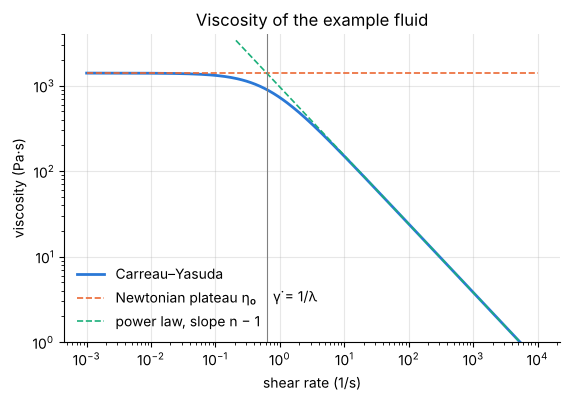

In [4]:
fluid = dict(eta0=1400.0, etainf=0.0, lam=1.6, n=0.2, a=1.25)
viscosity = sp.lambdify((gamma_dot, eta_0, eta_inf, lam, n, a), eta, "numpy")

def eta_of(rate, f=fluid):
    return viscosity(rate, f["eta0"], f["etainf"], f["lam"], f["n"], f["a"])

rates = np.logspace(-3, 4, 300)
fig, ax = plt.subplots()
ax.loglog(rates, eta_of(rates), label="Carreau–Yasuda")
ax.loglog(rates, np.full_like(rates, fluid["eta0"]), ls="--", lw=1.2, label="Newtonian plateau η₀")
ax.loglog(rates[rates > 0.2], fluid["eta0"] * (fluid["lam"] * rates[rates > 0.2]) ** (fluid["n"] - 1), ls="--", lw=1.2, label="power law, slope n − 1")
ax.axvline(1 / fluid["lam"], color="0.5", lw=0.8)
ax.annotate("γ̇ = 1/λ", xy=(1 / fluid["lam"], 3), xytext=(1 / fluid["lam"] * 1.25, 3))
ax.set(xlabel="shear rate (1/s)", ylabel="viscosity (Pa·s)", ylim=(1, 4000), title="Viscosity of the example fluid")
ax.legend(frameon=False, loc="lower left");

## 16.2 Why the method of notebook 6 fails

A force balance on a cylinder of fluid gives the shear stress at radius $r$ for **any** fluid,
$\tau = G r/2$, where $G$ is the pressure drop per unit length. With $\tau = \eta(\dot\gamma)\,\dot\gamma$
and $\dot\gamma = -du/dr$:

$$\eta(\dot\gamma)\,\dot\gamma = \frac{G\,r}{2}. \tag{1}$$

For a power-law fluid this was solved for $\dot\gamma(r)$ and integrated. For the
Carreau–Yasuda model, equation (1) cannot be solved for $\dot\gamma$ in closed form: the unknown
sits inside and outside a power with non-integer exponents.

**The key idea.** Equation (1) does give $r$ explicitly in terms of $\dot\gamma$. So use the
shear rate, not the radius, as the independent variable. Every quantity is then written
as a function of $\dot\gamma$, and the velocity profile is obtained in parametric form.

## 16.3 Scaling

Let $\dot\gamma_w$ be the shear rate at the wall and $\eta_w = \eta(\dot\gamma_w)$. Equation (1)
at $r = R$ reads $\eta_w\dot\gamma_w = GR/2$. Dividing (1) by this gives, with

$$s = \frac{\dot\gamma}{\dot\gamma_w},\quad \tilde r = \frac{r}{R},\quad
\tilde\eta = \frac{\eta}{\eta_w},\quad \tilde u = \frac{u}{R\,\dot\gamma_w},\quad
\Lambda = \lambda\dot\gamma_w,$$

the remarkably simple relation

$$\tilde r(s) = s\,\tilde\eta(s),\qquad 0 \le s \le 1 .$$

The parameter $s$ runs from 0 on the axis to 1 at the wall.

In [5]:
s, xi = sp.symbols("s xi", positive=True)
Lam = sp.symbols("Lambda", positive=True)
e0, einf = sp.symbols("etatilde_0 etatilde_inf", nonnegative=True)       # η₀/η_w and η∞/η_w

def shear_thinning(z):
    """The factor [1 + (Λ z)^a]^((n-1)/a), which carries all the non-Newtonian behaviour."""
    return (1 + (Lam * z) ** a) ** ((n - 1) / a)

def eta_tilde(z):
    return einf + (e0 - einf) * shear_thinning(z)

r_tilde = s * eta_tilde(s)
r_tilde

  ⎛                                 n - 1⎞
  ⎜                                 ─────⎟
  ⎜                                   a  ⎟
  ⎜                     ⎛     a    ⎞     ⎟
s⋅⎝η̃_inf + (η̃₀ - η̃_inf)⋅⎝(Λ⋅s)  + 1⎠     ⎠

## 16.4 The velocity profile

In scaled variables $d\tilde u/d\tilde r = -s$, and $\tilde u = 0$ at the wall ($s = 1$), so

$$\tilde u(s) = \int_{\tilde r(s)}^{1} s'\,d\tilde r' .$$

**By hand**, integrate by parts to move the derivative off $\tilde r$:

$$\tilde u(s) = 1 - s\,\tilde r(s) - \int_s^1 \xi\,\tilde\eta(\xi)\,d\xi . \tag{2}$$

**Check with SymPy, for any viscosity function at all.** Treat $\tilde\eta$ as an undefined
function and confirm that (2) has the right derivative and the right wall value.

In [6]:
any_eta = sp.Function("etatilde")
r_generic = s * any_eta(s)
u_generic = 1 - s * r_generic - sp.Integral(xi * any_eta(xi), (xi, s, 1))

assert sp.simplify(u_generic.diff(s) + s * r_generic.diff(s)) == 0        # du = -s dr
assert u_generic.subs(s, 1).doit().subs(any_eta(1), 1) == 0               # no slip, because η̃(1) = 1

Everything now rests on one integral, $\int \xi\,[1 + (\Lambda\xi)^a]^{(n-1)/a}\,d\xi$.
It has no elementary antiderivative for general $a$ and $n$. Notebook 13 said that a special
function is still a real answer, and SymPy finds it:

In [7]:
def tidy(expr):
    """Cancel the gamma functions and write exp_polar(iπ) as -1."""
    return sp.gammasimp(expr).replace(sp.exp_polar, sp.exp)

raw = sp.integrate(xi * shear_thinning(xi), (xi, 0, s))
raw

             ⎛2    n   1 │           ⎞
             ⎜─, - ─ + ─ │           ⎟
 2  ⎛2⎞  ┌─  ⎜a    a   a │  a  a  ⅈ⋅π⎟
s ⋅Γ⎜─⎟⋅ ├─  ⎜           │ Λ ⋅s ⋅ℯ   ⎟
    ⎝a⎠ 2╵ 1 ⎜      2    │           ⎟
             ⎜  1 + ─    │           ⎟
             ⎝      a    │           ⎠
──────────────────────────────────────
                 ⎛    2⎞              
              a⋅Γ⎜1 + ─⎟              
                 ⎝    a⎠              

In [8]:
half_Phi = tidy(raw)
half_Phi

        ⎛2  -(n - 1)  │       ⎞
        ⎜─, ───────── │       ⎟
 2  ┌─  ⎜a      a     │   a  a⎟
s ⋅ ├─  ⎜             │ -Λ ⋅s ⎟
   2╵ 1 ⎜   a + 2     │       ⎟
        ⎜   ─────     │       ⎟
        ⎝     a       │       ⎠
───────────────────────────────
               2               

This is $\tfrac12\Phi(s)$ with

$$\Phi(s) = s^2\;{}_2F_1\!\left(\frac{2}{a},\ \frac{1-n}{a};\ \frac{a+2}{a};\ -(\Lambda s)^a\right),$$

where ${}_2F_1$ is the Gauss hypergeometric function, the function that appears in the paper's
velocity formula. **Verify** in two independent ways: its Taylor series must match the
term-by-term integral of the integrand's series, and its derivative must equal the integrand
to 30 digits at an arbitrary point.

In [9]:
carreau = {a: 2}                                         # the series check is easiest for a = 2
series_of_result = sp.series(half_Phi.subs(carreau), s, 0, 8).removeO()
series_of_integrand = sp.integrate(sp.series((xi * shear_thinning(xi)).subs(carreau), xi, 0, 7).removeO(), (xi, 0, s))
assert sp.expand(series_of_result - series_of_integrand) == 0

point = {s: sp.Rational(3, 5), Lam: sp.Rational(7, 3), a: sp.Rational(5, 4), n: sp.Rational(1, 5)}
residual = (half_Phi.diff(s) - s * shear_thinning(s)).subs(point)
assert abs(sp.N(residual, 30)) < 1e-25

Assemble equation (2). The integral from $s$ to 1 is the difference of two antiderivative values.

In [10]:
def antiderivative(z):                                   # of ξ·η̃(ξ)
    return einf * z**2 / 2 + (e0 - einf) * half_Phi.subs(s, z)

u_tilde = 1 - s * r_tilde - (antiderivative(1) - antiderivative(s))
u_max_tilde = 1 - antiderivative(1)                      # centreline, s = 0
u_max_tilde

                            ⎛2  -(n - 1)  │    ⎞    
                            ⎜─, ───────── │    ⎟    
                        ┌─  ⎜a      a     │   a⎟    
          (η̃₀ - η̃_inf)⋅ ├─  ⎜             │ -Λ ⎟    
                       2╵ 1 ⎜   a + 2     │    ⎟    
                            ⎜   ─────     │    ⎟    
  η̃_inf                     ⎝     a       │    ⎠    
- ───── - ────────────────────────────────────── + 1
    2                       2                       

Together, $\tilde r(s)$ and $\tilde u(s)$ are the velocity profile in parametric form: pick a
value of $s$ between 0 and 1 and read off a radius and the velocity there.

## 16.5 The average velocity and the flow rate

$Q = \int_0^R 2\pi r\,u\,dr$, so the scaled average velocity is
$\tilde u_{avg} = 2\int_0^1 \tilde u\,\tilde r\,d\tilde r$.

**By hand**, integrate by parts twice (first to move the derivative onto $\tilde u$, then onto
$s$):

$$\tilde u_{avg} = \int_0^1 \tilde r^{\,2} s\,d\tilde r
= \frac13\left[1 - \int_0^1 \tilde r(s)^3\,ds\right]. \tag{3}$$

Since $\tilde r^3 = s^3\left[\tilde\eta_\infty + (\tilde\eta_0 - \tilde\eta_\infty)X\right]^3$
with $X$ the shear-thinning factor, the cube expands into four terms, and each is again a
hypergeometric integral that SymPy evaluates.

In [11]:
I = {k: tidy(sp.integrate(s**3 * shear_thinning(s) ** k, (s, 0, 1))) for k in (1, 2, 3)}
I[3]

     ⎛4  -3⋅(n - 1)  │    ⎞
     ⎜─, ─────────── │    ⎟
 ┌─  ⎜a       a      │   a⎟
 ├─  ⎜               │ -Λ ⎟
2╵ 1 ⎜    a + 4      │    ⎟
     ⎜    ─────      │    ⎟
     ⎝      a        │    ⎠
───────────────────────────
             4             

In [12]:
d = e0 - einf
integral_r_cubed = einf**3 / 4 + 3 * einf**2 * d * I[1] + 3 * einf * d**2 * I[2] + d**3 * I[3]
u_avg_tilde = (1 - integral_r_cubed) / 3

## 16.6 Checks before any numbers

**Newtonian limit.** With $n = 1$ the viscosity is constant, so $\tilde\eta_0 = 1$ and
$\tilde\eta_\infty$ drops out. The profile must be the parabola of notebook 6, with centreline
value $\tfrac12$ and average $\tfrac14$ in these units.

In [13]:
newtonian = {n: 1, e0: 1, einf: 0}
u_newton = sp.simplify(sp.hyperexpand(u_tilde.subs(newtonian)))
assert sp.simplify(r_tilde.subs(newtonian) - s) == 0                       # r̃ = s
assert sp.simplify(u_newton - (1 - s**2) / 2) == 0                         # so ũ = (1 - r̃²)/2
assert sp.hyperexpand(u_avg_tilde.subs(newtonian)) == sp.Rational(1, 4)
u_newton

     2
1   s 
─ - ──
2   2 

**Power-law limit.** At very high shear rate (with $\eta_\infty = 0$) the model becomes a power
law and $\tilde\eta = s^{\,n-1}$, so $\tilde r = s^n$. Equations (2) and (3) can then be
integrated in elementary terms, and must reproduce notebook 6:
$u/u_{avg}$ on the axis equal to $\dfrac{3n+1}{n+1}$.

In [14]:
r_pl = s**n
u_pl = sp.simplify(1 - s * r_pl - sp.integrate(xi * xi ** (n - 1), (xi, s, 1)))
u_avg_pl = sp.simplify((1 - sp.integrate(r_pl**3, (s, 0, 1))) / 3)
ratio_pl = sp.simplify(u_pl.subs(s, 0) / u_avg_pl)
assert sp.simplify(ratio_pl - (3 * n + 1) / (n + 1)) == 0
u_pl, u_avg_pl, ratio_pl

⎛  ⎛     n + 1⎞                  ⎞
⎜n⋅⎝1 - s     ⎠     n     3⋅n + 1⎟
⎜──────────────, ───────, ───────⎟
⎝    n + 1       3⋅n + 1   n + 1 ⎠

Since $s = \tilde r^{1/n}$, the profile is $\tilde u = \dfrac{n}{n+1}\left(1 - \tilde r^{(n+1)/n}\right)$,
the same shape as in notebook 6.

## 16.7 From formulas to numbers

`lambdify` does not know SymPy's `hyper` (notebook 8 met the same situation with an elliptic
integral), so supply SciPy's `hyp2f1`.

In [15]:
translation = [{"hyper": lambda upper, lower, z: hyp2f1(upper[0], upper[1], lower[0], z)}, "numpy"]
arguments = (Lam, e0, einf, n, a)

r_fun = sp.lambdify((s, *arguments), r_tilde, translation)
u_fun = sp.lambdify((s, *arguments), u_tilde, translation)
u_max_fun = sp.lambdify(arguments, u_max_tilde, translation)
u_avg_fun = sp.lambdify(arguments, u_avg_tilde, translation)

The **only numerical step** in the whole solution is finding the wall shear rate from
$\eta(\dot\gamma_w)\,\dot\gamma_w = GR/2$. The left side increases steadily with $\dot\gamma_w$,
so a bracketing root finder cannot fail (notebook 13.6).

In [16]:
def solve_pipe(G, R, f=fluid):
    """Wall shear rate, velocities and flow rate for pressure gradient G (Pa/m) and radius R (m)."""
    tau_wall = G * R / 2
    gamma_wall = brentq(lambda rate: eta_of(rate, f) * rate - tau_wall, tau_wall / f["eta0"] * 0.5, 1e12)
    eta_wall = eta_of(gamma_wall, f)
    reduced = (f["lam"] * gamma_wall, f["eta0"] / eta_wall, f["etainf"] / eta_wall, f["n"], f["a"])
    scale = R * gamma_wall                                 # velocity scale
    u_max, u_avg = scale * u_max_fun(*reduced), scale * u_avg_fun(*reduced)
    return dict(gamma_wall=gamma_wall, eta_wall=eta_wall, reduced=reduced, scale=scale,
                u_max=u_max, u_avg=u_avg, Q=np.pi * R**2 * u_avg, ratio=u_max / u_avg)

R_tube = 0.01                                              # m
result = solve_pipe(G=0.6e6, R=R_tube)                     # 0.6 MPa/m
for key in ("gamma_wall", "eta_wall", "u_max", "u_avg", "Q", "ratio"):
    print(f"{key:11s} {result[key]:.4g}")

gamma_wall  296.5
eta_wall    10.12
u_max       0.5
u_avg       0.3722
Q           0.0001169
ratio       1.343


**Verify against the published values.** For these conditions the author's reference
implementation, [carreau-yasuda-pipe-flow](https://github.com/ktwyw/carreau-yasuda-pipe-flow),
reports $\dot\gamma_w = 296.5$ s⁻¹, $u_{max} = 0.500$ m/s, $u_{avg} = 0.372$ m/s,
$Q = 1.169\times10^{-4}$ m³/s and $u_{max}/u_{avg} = 1.343$.

In [17]:
published = dict(gamma_wall=296.5, u_max=0.500, u_avg=0.372, Q=1.169e-4, ratio=1.343)
for key, value in published.items():
    assert abs(result[key] / value - 1) < 1e-3, key
print("all five published values reproduced to the digits quoted")

all five published values reproduced to the digits quoted


**Verify against brute force.** Forget the analysis. On a grid of radii, solve equation (1)
numerically for the local shear rate at every point, then integrate $du/dr = -\dot\gamma$ with
the trapezoidal rule. No hypergeometric functions, no change of variable.

In [18]:
def brute_force(G, R, f=fluid, points=4001):
    radii = np.linspace(0, R, points)
    local_rate = np.array([0.0] + [brentq(lambda rate: eta_of(rate, f) * rate - G * rr / 2, 0, 1e12) for rr in radii[1:]])
    from_axis = cumulative_trapezoid(local_rate, radii, initial=0)
    u = from_axis[-1] - from_axis                                         # u(R) = 0
    Q = np.trapezoid(2 * np.pi * radii * u, radii)
    return radii, u, Q

radii, u_brute, Q_brute = brute_force(0.6e6, R_tube)

s_grid = np.linspace(0, 1, 3000) ** 3            # parameter values, crowded towards the axis (s = 0)
r_param = R_tube * r_fun(s_grid, *result["reduced"])
u_param = result["scale"] * u_fun(s_grid, *result["reduced"])
u_on_grid = np.interp(radii, r_param, u_param)

print(f"largest difference in velocity: {np.abs(u_on_grid - u_brute).max():.1e} m/s   (u_max = {result['u_max']:.3f} m/s)")
print(f"flow rate: analytical {result['Q']:.6e}   brute force {Q_brute:.6e} m³/s")
assert np.abs(u_on_grid - u_brute).max() < 1e-5 * result["u_max"] and abs(Q_brute / result["Q"] - 1) < 1e-5

largest difference in velocity: 8.8e-08 m/s   (u_max = 0.500 m/s)
flow rate: analytical 1.169352e-04   brute force 1.169353e-04 m³/s


Three independent routes (limits, published numbers, brute force) agree. The analytical one
needed a single root-finding step; the brute-force one needed four thousand.

## 16.8 What the solution shows

**Velocity profiles.** At low pressure gradient the wall shear rate is far below $1/\lambda$,
the fluid is Newtonian everywhere and the profile is a parabola. At high pressure gradient most
of the cross-section is in the power-law regime and the profile flattens into a plug.

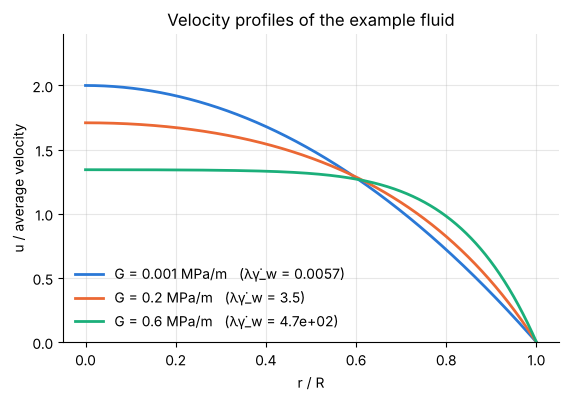

In [19]:
fig, ax = plt.subplots()
for G in (1e3, 2e5, 6e5):
    res = solve_pipe(G, R_tube)
    ax.plot(r_fun(s_grid, *res["reduced"]), u_fun(s_grid, *res["reduced"]) * res["scale"] / res["u_avg"],
            label=f"G = {G / 1e6:g} MPa/m   (λγ̇_w = {res['reduced'][0]:.2g})")
ax.set(xlabel="r / R", ylabel="u / average velocity", ylim=(0, 2.4), title="Velocity profiles of the example fluid")
ax.legend(frameon=False, loc="lower left");

**Centreline-to-average ratio.** One number summarizes the shape. It moves from the Newtonian
value 2 to the power-law value $(3n+1)/(n+1) = 4/3$ as the pressure gradient rises.

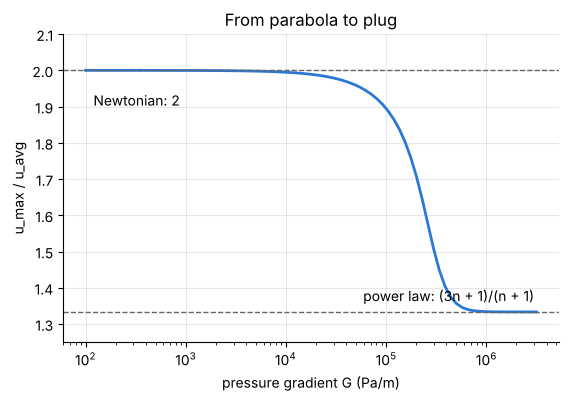

In [20]:
G_values = np.logspace(2, 6.5, 80)
sweep = [solve_pipe(G, R_tube) for G in G_values]
ratios = np.array([res["ratio"] for res in sweep])
power_law_ratio = (3 * fluid["n"] + 1) / (fluid["n"] + 1)
assert abs(ratios[0] - 2) < 1e-3 and abs(ratios[-1] - power_law_ratio) < 1e-3

fig, ax = plt.subplots()
ax.semilogx(G_values, ratios)
ax.axhline(2, color="0.4", lw=1, ls="--")
ax.axhline(power_law_ratio, color="0.4", lw=1, ls="--")
ax.annotate("Newtonian: 2", xy=(1e2, 2), xytext=(1.2e2, 1.94), va="top")
ax.annotate("power law: (3n + 1)/(n + 1)", xy=(3e6, power_law_ratio), xytext=(3e6, power_law_ratio + 0.03), ha="right")
ax.set(xlabel="pressure gradient G (Pa/m)", ylabel="u_max / u_avg", ylim=(1.25, 2.1), title="From parabola to plug");

**The flow curve.** For a Newtonian fluid, doubling the pressure gradient doubles the flow rate.
For this fluid in the power-law regime the flow rate grows as $G^{1/n} = G^5$: doubling the
pressure gradient multiplies the flow rate by 32. That sensitivity is why shear-thinning matters
so much in extrusion and injection moulding.

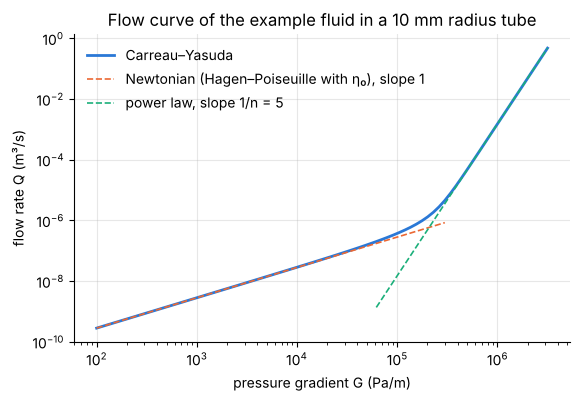

In [21]:
Q_values = np.array([res["Q"] for res in sweep])
Q_newton = np.pi * G_values * R_tube**4 / (8 * fluid["eta0"])
K_pl = fluid["eta0"] * fluid["lam"] ** (fluid["n"] - 1)                        # power-law consistency
Q_power = np.pi * fluid["n"] / (3 * fluid["n"] + 1) * R_tube**3 * (G_values * R_tube / (2 * K_pl)) ** (1 / fluid["n"])
assert abs(Q_values[0] / Q_newton[0] - 1) < 1e-2 and abs(Q_values[-1] / Q_power[-1] - 1) < 1e-2

fig, ax = plt.subplots()
ax.loglog(G_values, Q_values, label="Carreau–Yasuda")
ax.loglog(G_values[G_values < 3e5], Q_newton[G_values < 3e5], ls="--", lw=1.2, label="Newtonian (Hagen–Poiseuille with η₀), slope 1")
ax.loglog(G_values[G_values > 6e4], Q_power[G_values > 6e4], ls="--", lw=1.2, label="power law, slope 1/n = 5")
ax.set(xlabel="pressure gradient G (Pa/m)", ylabel="flow rate Q (m³/s)", title="Flow curve of the example fluid in a 10 mm radius tube")
ax.legend(frameon=False, loc="upper left");

## 16.9 The inverse problem

In practice the flow rate is often what is specified (by a pump or an extruder screw) and the
pressure gradient is what must be found. The flow curve rises steadily, so bracket and solve.
The Newtonian value is an upper bound but can be tens to hundreds of times too large for a
shear-thinning fluid, so the upper end of the bracket is found by stepping up in decades.

In [22]:
def pressure_gradient(Q_target, R, f=fluid):
    newtonian_estimate = 8 * f["eta0"] * Q_target / (np.pi * R**4)             # an upper bound, since η ≤ η₀
    upper = 1e-6 * newtonian_estimate
    while solve_pipe(upper, R, f)["Q"] < Q_target:                             # step up by decades until the root is bracketed
        upper *= 10
    return brentq(lambda G: solve_pipe(G, R, f)["Q"] - Q_target, 1e-9 * newtonian_estimate, upper)

G_needed = pressure_gradient(1.0e-4, R_tube)
assert abs(solve_pipe(G_needed, R_tube)["Q"] / 1.0e-4 - 1) < 1e-9
print(f"Q = 1.0e-4 m³/s needs G = {G_needed / 1e6:.3f} MPa/m "
      f"(a Newtonian fluid of viscosity η₀ would need {8 * fluid['eta0'] * 1e-4 / (np.pi * R_tube**4) / 1e6:.1f} MPa/m)")

Q = 1.0e-4 m³/s needs G = 0.581 MPa/m (a Newtonian fluid of viscosity η₀ would need 35.7 MPa/m)


## What this capstone illustrates

- **A change of variable can turn an unsolvable problem into a solvable one.** SymPy cannot
  find that idea for you. Once you have it, SymPy carries out and checks every step.
- **"No elementary antiderivative" is not the end.** The hypergeometric function is as usable
  as a sine: it has series, derivatives, limits and fast numerical implementations.
- **Verification is layered.** A generic identity (16.4), two limiting cases (16.6), published
  numbers and a brute-force computation (16.7) each test something different.
- **Symbolic and numerical work are partners.** One root-finding step was unavoidable, and
  everything else was exact.

The author's repository
[carreau-yasuda-pipe-flow](https://github.com/ktwyw/carreau-yasuda-pipe-flow) packages this
solution as a Python library with command-line tools and a browser calculator.

## Exercises

1. For the Carreau model ($a = 2$) the velocity integral is elementary. Evaluate
   $\int_0^s \xi\,[1 + (\Lambda\xi)^2]^{(n-1)/2}\,d\xi$ with SymPy and confirm numerically that
   it equals $\tfrac12\Phi(s)$ at $a = 2$.
2. Give the example fluid a high-shear plateau, $\eta_\infty = 1$ Pa·s. Plot $u_{max}/u_{avg}$
   against $G$ from $10^2$ to $10^{10}$ Pa/m. Explain why the ratio returns to 2.
3. Capillary rheometers report the apparent wall shear rate $\dot\gamma_a = 4Q/(\pi R^3)$,
   which is exact only for a Newtonian fluid. The Weissenberg–Rabinowitsch correction is
   $\dot\gamma_w = \dfrac{\dot\gamma_a}{4}\left(3 + \dfrac{d\ln\dot\gamma_a}{d\ln\tau_w}\right)$.
   Verify it numerically for the example fluid over the range of $G$ used in 16.8.
4. Repeat the derivation for pressure-driven flow between parallel plates a distance $2h$ apart,
   where $\tau = G\,y$. Show that $\tilde u(s)$ is unchanged and that
   $\tilde u_{avg} = \tfrac12\left[1 - \int_0^1 \tilde y(s)^2\,ds\right]$, and evaluate the
   integral with SymPy for $\eta_\infty = 0$.
5. For a fixed flow rate $Q = 10^{-4}$ m³/s, how does the required pressure gradient depend on
   the tube radius between 5 and 20 mm? Compare the slope on a log–log plot with the Newtonian
   value of $-4$, and explain the difference.